# FMNN25 Project 3 - Optimization

## Task 5 - Newton's method on the Rosenbrock function
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with exact linesearch.

fdiff > residual_tol 4.6686584065678013e-14
xdiff > cauchy_tol 2.688508850965496e-07
Computed minimum: [1. 1.]
f(x): 1.4750165579248397e-25
Iterations: 11


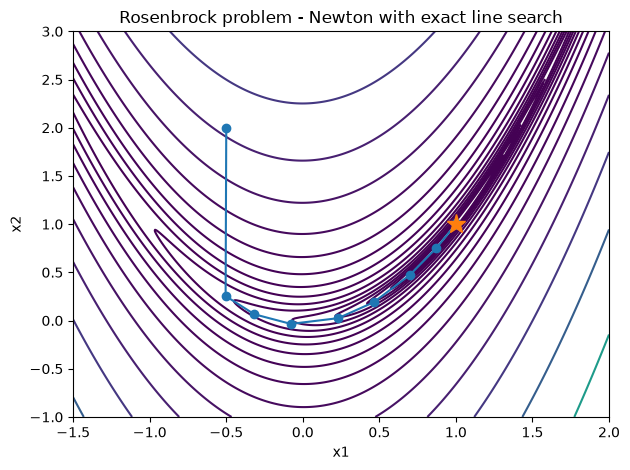

In [4]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithLineSearchMethod, \
                                           test_exact_linesearch


method = NewtonWithLineSearchMethod(rosenbrock_problem)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton with exact line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 7 - Minimizing the Rosenbrock function with inexact line search
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with an inexact linesearch.

Here, using Powell-Wolfe conditions following the algorithm presented in the course lecture.

fdiff > residual_tol 3.780331451884033e-09
Computed minimum: [1. 1.]
f(x): 1.4372463115940511e-15
Iterations: 16


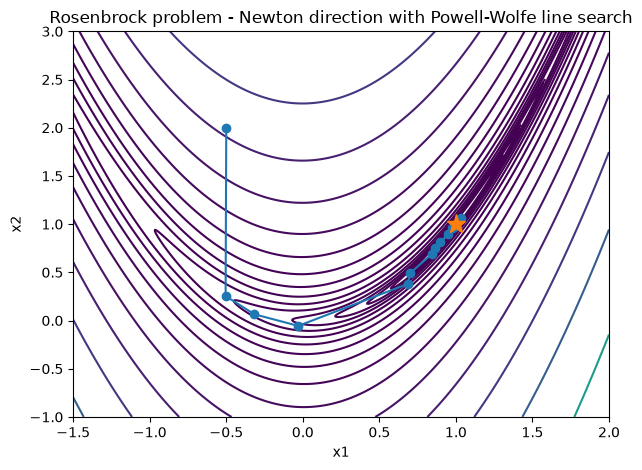

In [6]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithPowellWolfe, \
                                           test_exact_linesearch

# Note: implementation here uses lecture's notation and algorithm.
# Fletcher's book uses swapped sigma and rho.
method = NewtonWithPowellWolfe(rosenbrock_problem, sigma=0.01, rho=0.1, alpha_start=1.0)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton direction with Powell-Wolfe line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 11

Minimize the Chebyquad problem using a range of optimization methods.

In [ ]:
import scipy
import numpy as np
from optproblem_class import OptProblem
from chebyquad_problem import chebyquad, gradchebyquad
from quasinewton_methods import BFGS, DFP, SymmetricBroyden, BadBroyden, GoodBroyden
from newtons_and_linesearch_methods import NewtonsMethod, NewtonWithLineSearchMethod, NewtonWithPowellWolfe

print('\nTASK 11: Chebyquad, our BFGS vs scipy.optimize.fmin_bfgs')

for n in (4,8,11):
    prob=OptProblem(
        chebyquad,
        input_shape=n,
        grad=gradchebyquad
    )

    methods = {
        "Good Broyden" : GoodBroyden(prob),
        "Bad Broyden" : BadBroyden(prob),
        "Symmetric Broyden" : SymmetricBroyden(prob),
        "DFP" : DFP(prob),
        "BFGS" : BFGS(prob),
        "Newton" : NewtonsMethod(prob),
        "Newton exact linesearch" : NewtonWithLineSearchMethod(prob),
        "Newton Powell-Wolfe linesearch": NewtonWithPowellWolfe(prob, 
                                            sigma=0.01,
                                            rho=0.1,
                                            alpha_start=1.0)
    }

    x0 = np.linspace(0,1,n)

    solve_kwargs = {
        "x0" : x0,
        "residual_tol" : 1e-8,
        "cauchy_tol" : 1e-5,
        "max_steps" : 20
    }

    solutions = {k:m.solve(**solve_kwargs) for k,m in methods.items()}

    # include scipy bfgs:
    solutions["scipy BFGS"] = scipy.optimize.fmin_bfgs(
        prob.f,
        x0,
        fprime=prob.grad,
        disp=False,
        maxiter=500
        )

    print("\n"*3 + "*"*40)
    print("*"*10 + f"{' Done!':^20}" + "*"*10)
    print("*"*40 + "\n"*2)

    print("\n\n".join((
                      f"{k}," +\
                      (f"\nIterations: {methods[k].steps}" if k in methods else "") +\
                      (f"\nExecution Time (s): {sum(methods[k].exec_time_history)*10**-9:.5f}" if k in methods else "") +\
                      f"\nf: {prob(x)}," +\
                      f"\nx: {x}"
                      ) for k,x in solutions.items()))


TASK 11: Chebyquad, our BFGS vs scipy.optimize.fmin_bfgs
s_k [ 1.77777778  0.59259259 -0.59259259 -1.77777778]
0.4991053132375991
x [0.         0.33333333 0.66666667 1.        ]
H: [[ 0.77459739 -0.0751342   0.0751342   0.22540261]
 [-0.0751342   0.97495527  0.02504473  0.0751342 ]
 [ 0.0751342   0.02504473  0.97495527 -0.0751342 ]
 [ 0.22540261  0.0751342  -0.0751342   0.77459739]]
s_k [-1.27123893e-10 -4.23766422e-11  4.23742497e-11  1.27128783e-10]
0.18783612215257853
x [0.88729833 0.62909944 0.37090056 0.11270167]
H: [[ 0.5922122  -0.13593493  0.13592813  0.40780203]
 [-0.13594376  0.95468352  0.04531421  0.13594851]
 [ 0.13592655  0.04531074  0.95469153 -0.1359313 ]
 [ 0.40782308  0.13594669 -0.13593989  0.59216269]]
fdiff > residual_tol 6.75795745754155e-21
xdiff > cauchy_tol 3.559658865254937e-11
s_k [ 1.77777778  0.59259259 -0.59259259 -1.77777778]
0.4991053132375991
x [0.         0.33333333 0.66666667 1.        ]
H: [[ 0.77459739 -0.0751342   0.0751342   0.22540261]
 [-0.0751

c:\Users\Ludwig\Documents\Code\fmnn25f-project3\quasinewton_methods.py:58: RuntimeWarning: invalid value encountered in divide
  self.H = self.H + (np.outer(delta_k - self.H @ gamma_k, gamma_k)/(gamma_k@gamma_k))
c:\Users\Ludwig\Documents\Code\fmnn25f-project3\quasinewton_methods.py:70: RuntimeWarning: divide by zero encountered in scalar divide
  a_k = 1/(u_k@gamma_k)
c:\Users\Ludwig\Documents\Code\fmnn25f-project3\quasinewton_methods.py:72: RuntimeWarning: invalid value encountered in multiply
  self.H = self.H + a_k*np.outer(u_k, u_k)


H: [[ 5.20705164e-01  9.50049131e-04 -2.16312521e-03 -2.92082793e-02
   2.92082793e-02  2.16312521e-03 -9.50049131e-04  4.79294836e-01]
 [ 9.50049131e-04  5.29674804e-01  6.39124635e-02 -3.82978226e-02
   3.82978226e-02 -6.39124635e-02  4.70325196e-01 -9.50049131e-04]
 [-2.16312521e-03  6.39124635e-02  9.60990207e-01 -3.11598842e-01
   3.11598842e-01  3.90097931e-02 -6.39124635e-02  2.16312521e-03]
 [-2.92082793e-02 -3.82978226e-02 -3.11598842e-01  8.82805473e-01
   1.17194527e-01  3.11598842e-01  3.82978226e-02  2.92082793e-02]
 [ 2.92082793e-02  3.82978226e-02  3.11598842e-01  1.17194527e-01
   8.82805473e-01 -3.11598842e-01 -3.82978226e-02 -2.92082793e-02]
 [ 2.16312521e-03 -6.39124635e-02  3.90097931e-02  3.11598842e-01
  -3.11598842e-01  9.60990207e-01  6.39124635e-02 -2.16312521e-03]
 [-9.50049131e-04  4.70325196e-01 -6.39124635e-02  3.82978226e-02
  -3.82978226e-02  6.39124635e-02  5.29674804e-01  9.50049131e-04]
 [ 4.79294836e-01 -9.50049131e-04  2.16312521e-03  2.92082793e-02


c:\Users\Ludwig\Documents\Code\fmnn25f-project3\quasinewton_methods.py:47: RuntimeWarning: invalid value encountered in divide
  self.H = self.H + (np.outer((delta_k - self.H@gamma_k), (delta_k@self.H))/(numerator))


H: [[ 5.10452847e-01  2.04110327e-02 -2.94203002e-02  2.75687284e-02
   5.32349278e-04 -1.34405540e-17 -5.32349278e-04 -2.75687284e-02
   2.94203002e-02 -2.04110327e-02  4.89547153e-01]
 [ 2.04110327e-02  9.99148988e-01  1.22664121e-03 -1.14944232e-03
  -2.21956117e-05  5.60386443e-19  2.21956117e-05  1.14944232e-03
  -1.22664121e-03  8.51011500e-04 -2.04110327e-02]
 [-2.94203002e-02  1.22664121e-03  9.98231929e-01  1.65679702e-03
   3.19925782e-05 -8.07736561e-19 -3.19925782e-05 -1.65679702e-03
   1.76807088e-03 -1.22664121e-03  2.94203002e-02]
 [ 2.75687284e-02 -1.14944232e-03  1.65679702e-03  9.98447474e-01
  -2.99791196e-05  7.56901518e-19  2.99791196e-05  1.55252621e-03
  -1.65679702e-03  1.14944232e-03 -2.75687284e-02]
 [ 5.32349278e-04 -2.21956117e-05  3.19925782e-05 -2.99791196e-05
   9.99999421e-01  1.46156896e-20  5.78893682e-07  2.99791196e-05
  -3.19925782e-05  2.21956117e-05 -5.32349278e-04]
 [-1.34405540e-17  5.60386443e-19 -8.07736561e-19  7.56901518e-19
   1.46156896e-2

## Task 12

Study the approximation quality of the BFGS method's estimated inverse Hessian.